# UCL Fantasy: forecasting component rates from domestic-league performance

**Idea.** Fantasy points are a sum of per-game events (appearance, goals, assists, clean sheets, cards...). Instead of regressing season totals,
we forecast each *rate* (goals/90, assists/90, minutes per appearance, share of club games played, clean-sheet rate, ...) for a player's UCL season `T`
from his **domestic-league season `T-1`**, then convert rates to expected fantasy points with the scoring rules.

Process (Forecasting course): (1) look at the data, (2) fit models per position, (3) evaluate **out of sample** with an expanding window and compare with naive benchmarks,
(4) check for a structural break (2024/25 format change), (5) forecast.

Data: Transfermarkt open dataset (CC0), UEFA's archived official fantasy feeds. Build scripts are in `scripts/`.

In [1]:
import sys, re, unicodedata, warnings; sys.path.insert(0, 'scripts'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import ratemodel as rm
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
st  = pd.read_csv('data/tm_stints.csv'); ctx = pd.read_csv('data/tm_club_dom_context.csv'); off = pd.read_csv('data/uefa_official_ucl.csv')
panel = rm.build_panel(st, ctx); dom, cl = rm.prepare_stints(st)
ORIGINS = [2021, 2022, 2023, 2024, 2025]
print(panel.shape); panel.groupby(['season','pos']).size().unstack()

(4065, 45)


pos,DEF,FWD,GK,MID
season,,,,
2018,184,125,29,147
2019,171,121,30,146
2020,175,125,35,156
2021,187,129,31,162
2022,178,122,34,138
2023,184,143,35,150
2024,203,140,45,162
2025,208,159,43,168


## 1. Data: the panel
One row per player-season: target = UCL season `T` rates, inputs = same player's domestic season `T-1` (>= 450 minutes). Seasons are start years (2025 = 2025/26).

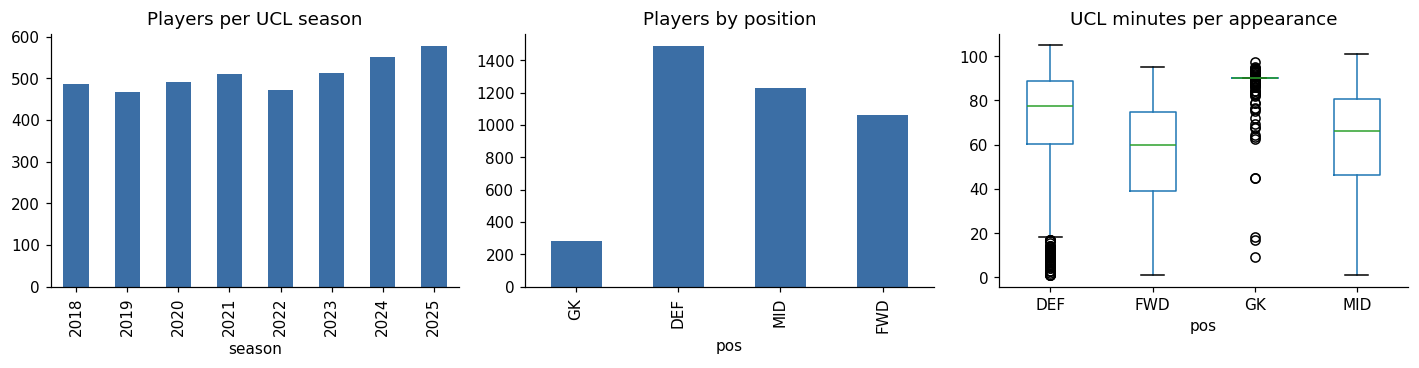

In [2]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
panel.groupby('season').size().plot.bar(ax=ax[0], color='#3b6ea5'); ax[0].set_title('Players per UCL season')
panel.pos.value_counts().reindex(['GK','DEF','MID','FWD']).plot.bar(ax=ax[1], color='#3b6ea5'); ax[1].set_title('Players by position')
panel.assign(mpa=panel.minutes/panel.apps).boxplot(column='mpa', by='pos', ax=ax[2], grid=False); ax[2].set_title('UCL minutes per appearance'); plt.suptitle('')
plt.tight_layout(); plt.show()

## 2. Visualise: does domestic form carry over?
Raw domestic goals/90 is noisy, especially for players with few minutes. We shrink it toward the position mean: `(goals + k*mu)/(nineties + k)`.

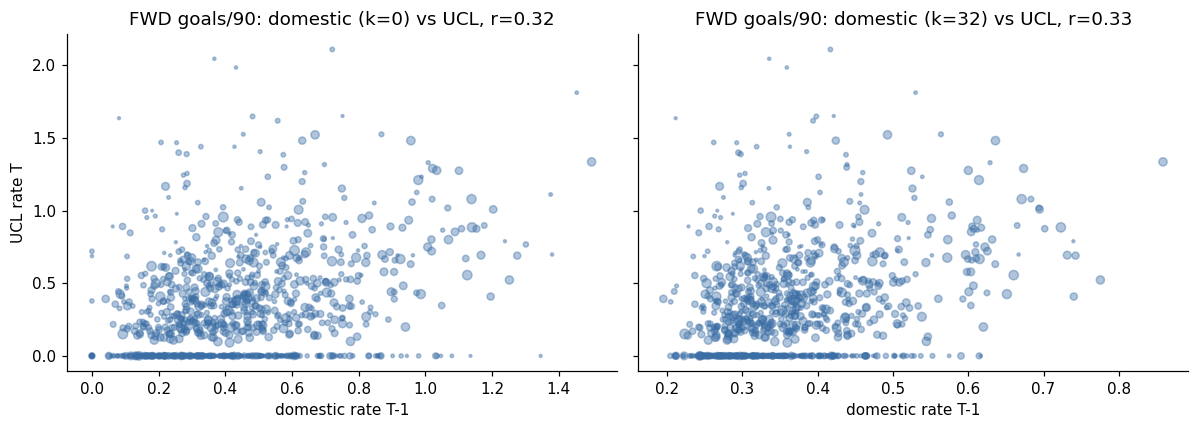

In [3]:
P = panel[panel.pos=='FWD'].copy(); P['d_nineties'] = P.d_minutes/90
P = P[(P.nineties>=1)&(P.d_nineties>=5)]
mu = rm.pop_mu(dom, 'g90', 'FWD', 2025)
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, k in zip(ax, [0, 32]):
    x = (P.d_goals + k*mu)/(P.d_nineties + k); y = P.goals/P.nineties
    a.scatter(x, y, s=P.nineties*3, alpha=.4, color='#3b6ea5'); a.set_title(f'FWD goals/90: domestic (k={k}) vs UCL, r={np.corrcoef(x,y)[0,1]:.2f}')
    a.set_xlabel('domestic rate T-1')
ax[0].set_ylabel('UCL rate T'); plt.tight_layout(); plt.show()

## 3. Fit & evaluate out of sample
For each component and position we fit WLS (weights = exposure) on all seasons before origin `T0` and predict season `T0`. Features: shrunk own rate, age, age², league strength, club's domestic goals for/against per game, sub-position dummies. Candidates: shrinkage `k` in a grid, or just the training mean. The candidate used at origin `T0` is chosen **only from errors at earlier origins** (no look-ahead). Benchmarks: training mean and raw domestic rate.

In [4]:
errs = rm.grid_errors(panel, dom, ORIGINS)
honest = rm.honest_table(errs); summ = rm.summarize(honest, first_origin=2023)
summ.round(3).pivot(index='comp', columns='pos', values='R2_model')

pos,DEF,FWD,GK,MID
comp,,,,
a90,0.098,-0.026,NaN,0.099
apps_share,0.043,0.058,0.188,0.067
cs_rate,-0.010,NaN,0.000,-0.011
g90,0.000,0.205,NaN,0.139
gc90,-0.034,NaN,-0.094,NaN
mpa,0.098,0.146,0.012,0.189
p60,0.097,0.138,0.002,0.160
yc90,0.039,0.054,0.000,0.051


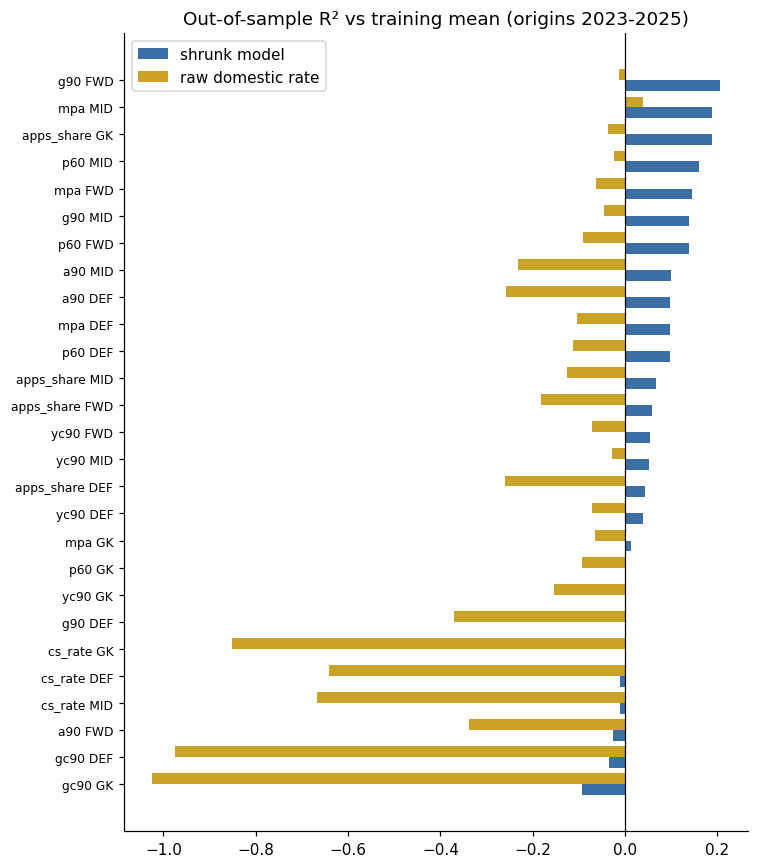

,comp,pos,n,R2_model,R2_raw_domestic,choice
0,a90,DEF,595,0.098,-0.257,k=128
1,a90,FWD,442,-0.026,-0.337,mean
2,a90,MID,480,0.099,-0.231,k=128
3,apps_share,DEF,595,0.043,-0.260,k=0
4,apps_share,FWD,442,0.058,-0.181,k=128
5,apps_share,GK,123,0.188,-0.037,k=128
6,apps_share,MID,480,0.067,-0.126,k=8
7,cs_rate,DEF,555,-0.010,-0.641,k=0
8,cs_rate,GK,120,0.000,-0.851,mean
9,cs_rate,MID,438,-0.011,-0.668,k=128


In [5]:
s = summ.assign(label=summ.comp+' '+summ.pos).sort_values('R2_model')
fig, ax = plt.subplots(figsize=(7, 8)); y = np.arange(len(s))
ax.barh(y-.2, s.R2_model, .4, label='shrunk model', color='#3b6ea5'); ax.barh(y+.2, s.R2_raw_domestic, .4, label='raw domestic rate', color='#c9a227')
ax.set_yticks(y); ax.set_yticklabels(s.label, fontsize=8); ax.axvline(0, color='k', lw=.8); ax.legend()
ax.set_title('Out-of-sample R² vs training mean (origins 2023-2025)'); plt.tight_layout(); plt.show()
summ.round(3)

**Reading this.** Positive = beats "predict the position mean". Raw domestic rates are *worse* than the mean almost everywhere (too noisy);
shrinkage turns them into useful forecasts for goals (FWD/MID), assists, minutes per appearance and availability. Clean-sheet rate and goals conceded have no skill
beyond the mean (these depend on the opponent draw, not the player), so the model correctly falls back to the mean.

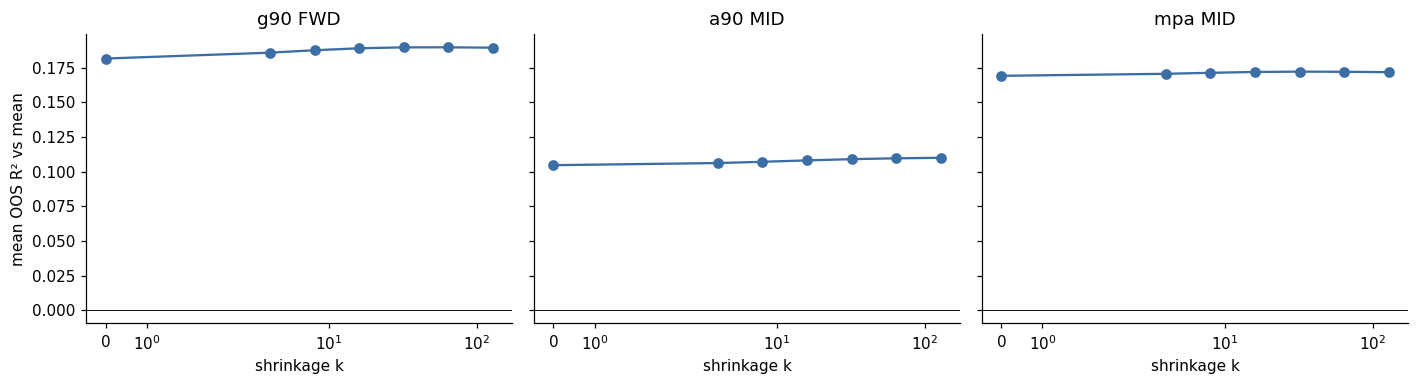

In [6]:
sh = errs[errs.cand!=rm.MEAN].assign(r2=lambda d: 1-d.mse/d.mse_mean)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for a, (c, p) in zip(ax, [('g90','FWD'), ('a90','MID'), ('mpa','MID')]):
    g = sh[(sh.comp==c)&(sh.pos==p)].groupby('cand').r2.mean(); a.plot(g.index, g.values, 'o-', color='#3b6ea5'); a.set_xscale('symlog', linthresh=4)
    a.set_title(f'{c} {p}'); a.set_xlabel('shrinkage k'); a.axhline(0, color='k', lw=.6)
ax[0].set_ylabel('mean OOS R² vs mean'); plt.tight_layout(); plt.show()

### Coefficients (final fit on all seasons through 2025, FWD goals/90, k=32)

In [7]:
P = panel[panel.pos=='FWD']
_, _, fit = rm.fit_predict(P, P.head(5), 'g90', 'FWD', 32, dom, 2025, return_fit=True)
pd.DataFrame({'coef': fit.params, 'se': fit.bse, 't': fit.tvalues}).round(3)

,coef,se,t
const,0.029,0.340,0.085
own,1.042,0.103,10.134
age,-0.025,0.026,-0.973
age2,0.000,0.000,0.695
lstr,0.013,0.002,6.676
gf,0.105,0.024,4.373
ga,-0.029,0.043,-0.676
Left Winger,-0.117,0.027,-4.352
Right Winger,-0.099,0.026,-3.772
Second Striker,0.029,0.041,0.713


## 4. Structural break: the 2024/25 format change
UCL moved from 6 group games to an 8-game league phase in 2024/25. Rates are per 90 or per club game, so they should be unaffected, but we check: do out-of-sample forecast errors
(actual - predicted) have a different mean before and after the change (Welch t-test on player-level errors, origins 2021-23 vs 2024-25)?

In [8]:
preds = {T0: rm.predict_components(panel, dom, errs, T0) for T0 in ORIGINS}
rows = []
for comp in ['apps_share', 'mpa', 'p60', 'g90', 'a90']:
    pre, post = [], []
    for T0, t in preds.items():
        y = rm.target_rate(comp, t); ok = y.notna() & t[f'p_{comp}'].notna()
        (post if T0 >= 2024 else pre).extend((y-t[f'p_{comp}'])[ok].tolist())
    tt = stats.ttest_ind(pre, post, equal_var=False)
    rows.append(dict(comp=comp, err_pre=np.mean(pre), err_post=np.mean(post), t=tt.statistic, p=tt.pvalue))
pd.DataFrame(rows).round(4)

,comp,err_pre,err_post,t,p
0,apps_share,0.0212,0.0032,1.7948,0.0728
1,mpa,-4.9879,-4.1201,-1.0823,0.2792
2,p60,-0.0738,-0.0637,-0.8875,0.3749
3,g90,0.0047,-0.0043,0.4668,0.6407
4,a90,-0.0147,-0.0062,-0.9652,0.3346


A significant difference would justify a break dummy; otherwise pooling across the change is fine. (Only 2 post-break origins, so power is limited; treat as a sanity check.)

## 5. From rates to fantasy points
Expected points per appearance = `1 + P(60+ min) + goal_w*g90*m + 3*a90*m + cs_w*cs_rate*p60 - 0.5*gc90*m - yc90*m + other90*m`, with `m = minutes per appearance / 90`.
`other90` (balls recovered, saves, player-of-match, penalties...) is not available in the domestic data, so it is a **position-level** points/90 calibrated on *earlier* official UEFA seasons.
Season total = availability x club games x points per appearance.

Validation against the **official UEFA season totals** for 2024 and 2025 (other90 calibrated only on earlier seasons, using the true number of club games):

In [9]:
res = []
for T0 in [2024, 2025]:
    t = preds[T0].copy()
    o90 = rm.other_points_per90(off, st, T0-1)
    t['xpts'], t['xppa'] = rm.expected_points(t, t.pos, t.club_games, o90)
    t = t.merge(off[off.season==T0][['tm_player_id','totPts']], left_on='player_id', right_on='tm_player_id', how='inner')
    prev = panel[panel.season<T0].merge(off[['tm_player_id','season','totPts']], left_on=['player_id','season'], right_on=['tm_player_id','season'])
    ppg = prev.groupby('pos').totPts.sum() / prev.groupby('pos').club_games.sum()
    t['bench'] = t.pos.map(ppg) * t.club_games
    res.append(t.assign(T0=T0))
V = pd.concat(res)
r2 = lambda y, p: 1 - ((y-p)**2).sum()/((y-y.mean())**2).sum()
out = V.groupby(['T0','pos']).apply(lambda g: pd.Series({'n': len(g), 'R2 model': r2(g.totPts, g.xpts), 'R2 pos-mean bench': r2(g.totPts, g.bench),
      'MAE model': (g.totPts-g.xpts).abs().mean(), 'MAE bench': (g.totPts-g.bench).abs().mean(), 'corr': g.totPts.corr(g.xpts)}))
out.round(2)

n  R2 model  R2 pos-mean bench  MAE model  MAE bench  corr
T0   pos                                                                
2024 DEF  196.0      0.25               0.15      13.97      14.83  0.50
     FWD  133.0      0.27               0.19      14.81      16.26  0.56
     GK    43.0      0.17               0.05      13.05      14.18  0.43
     MID  155.0      0.25               0.14      11.43      12.22  0.52
2025 DEF  195.0      0.05               0.05      11.93      12.11  0.32
     FWD  144.0      0.37               0.18      12.93      14.88  0.63
     GK    41.0      0.09              -0.01      11.39      12.36  0.36
     MID  163.0      0.24               0.09      11.37      12.47  0.49

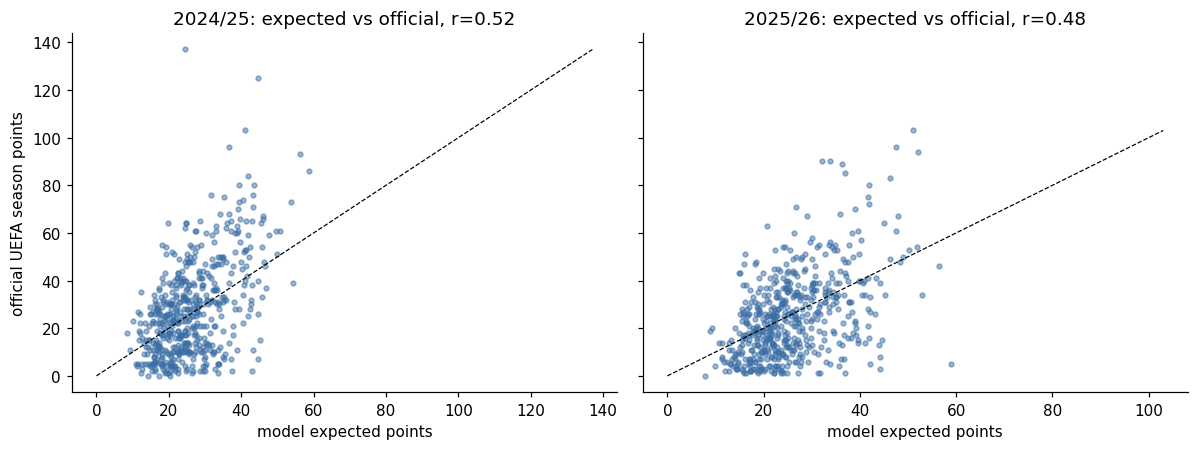

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for a, T0 in zip(ax, [2024, 2025]):
    g = V[V.T0==T0]; a.scatter(g.xpts, g.totPts, s=10, alpha=.5, color='#3b6ea5'); m = max(g.xpts.max(), g.totPts.max()); a.plot([0, m], [0, m], 'k--', lw=.8)
    a.set_title(f'{T0}/{T0+1-2000}: expected vs official, r={g.totPts.corr(g.xpts):.2f}'); a.set_xlabel('model expected points')
ax[0].set_ylabel('official UEFA season points'); plt.tight_layout(); plt.show()

## 6. Forecast 2026/27
Inputs: each player's 2025/26 domestic season. The model is trained on all UCL seasons up to 2025. Club games are assumed to be 8 (league phase only), so totals are a floor for teams that go deeper.

In [11]:
d = dom[dom.season==2025].copy()
F = d.rename(columns=lambda c: c if c=='player_id' else f'd_{c}')
F['season'] = 2026; F['club_id'] = F.d_club_id; F['pos'] = F.d_pos
c = ctx[ctx.season==2025][['club_id','gf_pg','ga_pg']].drop_duplicates('club_id')
F = F.merge(c, on='club_id', how='left'); F['league_strength'] = [rm.league_strength(l, 2025) for l in F.d_league]; F['age2'] = F.d_age**2
F['club_games'] = 8
allp = pd.concat([panel, F], ignore_index=True)
T = rm.predict_components(allp, dom, errs, 2026)
o90 = rm.other_points_per90(off, st, 2025); print('other points per 90:', {k: round(v,2) for k,v in o90.items()})
T['xpts'], T['xppa'] = rm.expected_points(T, T.pos, T.club_games, o90)
print(len(T), 'players forecast;', T.xpts.notna().sum(), 'with a full forecast')

other points per 90: {'DEF': 1.68, 'FWD': 0.53, 'GK': 1.23, 'MID': 1.0}
3950 players forecast; 3950 with a full forecast


Match to the current UEFA fantasy player pool by name (UEFA uses abbreviated names like `K. Mbappé`; ties go to the most-played candidate at the same position).

In [12]:
norm = lambda s: re.sub(r'[^a-z ]', '', unicodedata.normalize('NFKD', str(s)).encode('ascii','ignore').decode().lower()).strip()
pool = pd.read_csv('data/uefa_fantasy_player_pool.csv'); pool['nn'] = pool.Name.map(norm)
T['nn'] = T.d_name.map(norm); T = T.sort_values('d_minutes', ascending=False)
def find(r):
    toks = r.nn.split()
    if not toks: return np.nan
    cand = T[(T.pos==r.Position) & T.nn.map(lambda n: bool(n.split()) and (n.split()[-1]==toks[-1] or n==r.nn))]
    if len(toks) > 1:
        cand = cand[cand.nn.str.startswith(toks[0][:1])]  # first initial must agree (N. Kane != Harry Kane)
    return cand.player_id.iloc[0] if len(cand) else np.nan
pool['player_id'] = pool.apply(find, axis=1)
M = pool.merge(T[['player_id','d_name','d_league','xpts','xppa','p_apps_share','p_mpa','p_g90','p_a90']].drop_duplicates('player_id'), on='player_id', how='left')
print('pool matched:', round(M.player_id.notna().mean(), 3), '| with forecast:', round(M.xpts.notna().mean(), 3))
M['pts_per_m'] = M.xpts / M.Price
M.drop(columns='nn').to_csv('out/rate_model_forecast_2627.csv', index=False)
top = M.sort_values('xpts', ascending=False).groupby('Position').head(8)
top[['Position','Name','Price','d_league','p_apps_share','p_g90','p_a90','xppa','xpts','pts_per_m']].round(2).sort_values(['Position','xpts'], ascending=[True, False])

pool matched: 0.492 | with forecast: 0.492


,Position,Name,Price,d_league,p_apps_share,p_g90,p_a90,xppa,xpts,pts_per_m
717,DEF,Gonçalo Inácio,4.5,PO1,0.75,0.05,0.07,4.43,26.53,5.90
544,DEF,Eric García,4.5,ES1,0.75,0.05,0.06,4.27,25.50,5.67
245,DEF,W. Saliba,5.5,GB1,0.69,0.05,0.06,4.55,25.27,4.60
574,DEF,J. Bednarek,4.5,PO1,0.76,0.05,0.04,4.13,25.22,5.61
550,DEF,W. Anton,4.5,L1,0.74,0.05,0.04,4.25,25.19,5.60
453,DEF,Matheus Nunes,5.0,GB1,0.69,0.05,0.17,4.49,24.96,4.99
478,DEF,J. Tah,5.0,L1,0.72,0.05,0.07,4.32,24.92,4.98
404,DEF,F. Dimarco,5.0,IT1,0.74,0.05,0.21,4.16,24.79,4.96
2,FWD,H. Kane,11.0,L1,0.81,1.03,0.30,5.86,38.19,3.47
71,FWD,L. Suárez,7.0,PO1,0.77,0.77,0.25,5.02,30.74,4.39


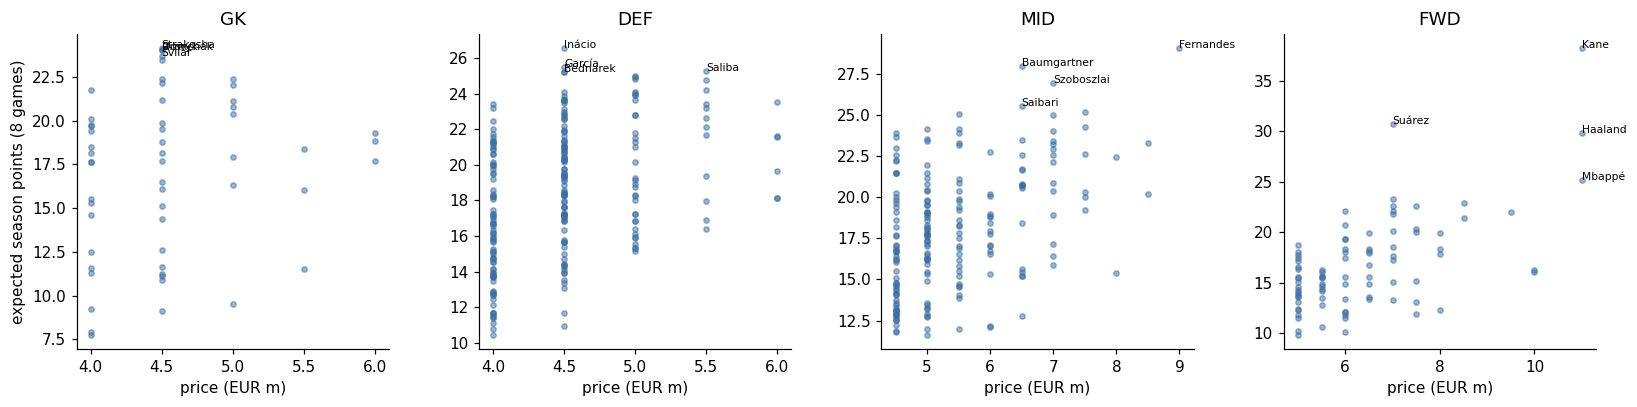

In [13]:
fig, ax = plt.subplots(1, 4, figsize=(15, 3.8))
for a, p in zip(ax, ['GK','DEF','MID','FWD']):
    g = M[(M.Position==p)&M.xpts.notna()]; a.scatter(g.Price, g.xpts, s=12, alpha=.5, color='#3b6ea5')
    for _, r in g.nlargest(4, 'xpts').iterrows(): a.annotate(r.Name.split()[-1], (r.Price, r.xpts), fontsize=7)
    a.set_title(p); a.set_xlabel('price (EUR m)')
ax[0].set_ylabel('expected season points (8 games)'); plt.tight_layout(); plt.show()

## 7. Limitations
- **Coverage**: Transfermarkt has no domestic data for Austria, Norway, Czechia, Slovakia, Azerbaijan, so players of those clubs (and new signings from other leagues) get no forecast.
- **Balls recovered, saves, player-of-the-match** are not in the data: they enter only as a position-average `other90`. Defenders' and keepers' individual differences in these are therefore missed (the largest remaining error source).
- **Clean sheets / goals conceded** are approximated at game level and have no predictive skill beyond the mean; team strength features are weak proxies for the opponent draw.
- **Transfers** between the domestic season and UCL are ignored (club context is last season's club). Injuries are not modelled.
- Only 3-5 expanding-window origins, so evaluation is by player-level pooled errors rather than a Diebold-Mariano test.
- Club games for 2026/27 fixed at 8: teams that reach the knockouts will score more.